# PTM3D Tutorial 01 — A global lunar diurnal run

A self-contained walkthrough of PTM3D's smallest end-to-end example: one full
lunar day (a synodic month, 29.53 Earth days) of surface temperature over the
*entire* Moon on a coarse global mesh. It is the notebook counterpart of
[`docs/tutorials/02_lunar_diurnal_icosphere.md`](../02_lunar_diurnal_icosphere.md)
and the README ["Get started"](../../../README.md#get-started) walkthrough —
same config, same binary.

## What you'll learn

- How a PTM3D YAML config maps to a simulation (body, mesh, time span,
  thermophysical properties, output).
- How to run `ptm_thermal_sim` from Python and stream its progress.
- The on-disk output format (`statistics/*.bin`, per-timestep snapshots,
  `mesh.ply`) and how to read it with the Python standard library and NumPy.
- How to make a temperature map, a diurnal temperature curve, and a
  day/night-contrast plot from that output.
- Why the lunar surface swings from ~385 K at noon to ~66 K before dawn, and
  why the drop is gradual rather than instant (thermal inertia).

**Cost:** CPU-only, well under a minute, <1 GB RAM. The run is a 1280-face
icosphere with radiation exchange off (a convex sphere has no self-view), so
no GPU and no view-factor matrix are involved.

**Prerequisite:** a built `ptm_thermal_sim` binary and the Moon SPICE kernels
— see the repo README's [**Get started**](../../../README.md#get-started)
section (steps 0-3). The next cell checks for both and prints the command to
run if either is missing.


## 0. Environment check

Checks, in order: Python version, the two packages this notebook needs
(`numpy`, `matplotlib`), the `ptm_thermal_sim` binary, and the SPICE kernels.
Each failure prints the command that fixes it.


In [1]:
import sys

print(f"Python {sys.version.split()[0]} ({sys.executable})")
if sys.version_info < (3, 8):
    print(f"WARNING: PTM3D's own helper scripts need Python >= 3.8 "
          f"(README 'Prerequisites' table); you have {sys.version_info}.")

missing = []
try:
    import numpy as np
    print(f"numpy      {np.__version__}  OK")
except ImportError:
    missing.append("numpy")
    print("numpy      MISSING")

try:
    import matplotlib
    import matplotlib.pyplot as plt
    print(f"matplotlib {matplotlib.__version__}  OK")
except ImportError:
    missing.append("matplotlib")
    print("matplotlib MISSING")

if missing:
    print()
    print("Missing required package(s):", ", ".join(missing))
    print(f"  Proposed fix: {sys.executable} -m pip install {' '.join(missing)}")
    raise ImportError(
        f"Install the package(s) above, then Kernel > Restart and re-run: {missing}"
    )

# PyYAML is optional: it gives a structured view of the config in the next
# section; without it the raw YAML text is shown instead.
try:
    import yaml
    HAVE_YAML = True
    print(f"PyYAML     {yaml.__version__}  OK (optional)")
except ImportError:
    HAVE_YAML = False
    print("PyYAML     not found (optional) -- config walkthrough will show")
    print(f"           raw YAML text only. To enable structured display:")
    print(f"             {sys.executable} -m pip install pyyaml")


Python 3.8.18 (/Users/paha3326/anaconda3/envs/europa_viz/bin/python)
numpy      1.24.4  OK


matplotlib 3.7.5  OK
PyYAML     6.0.2  OK (optional)


In [2]:
from pathlib import Path


def find_repo_root(start: Path) -> Path:
    '''Walk up from `start` looking for the PTM3D repo root.

    Works whether Jupyter was launched from the repo root or from this
    notebook's own directory (docs/tutorials/notebooks/).
    '''
    for cand in [start.resolve(), *start.resolve().parents]:
        if (cand / "CMakeLists.txt").exists() and (cand / "examples").is_dir():
            return cand
    raise RuntimeError(
        f"Could not locate the PTM3D repo root by walking up from {start}. "
        "Open this notebook from inside a PTM3D clone."
    )


REPO_ROOT = find_repo_root(Path.cwd())
print("Repo root:", REPO_ROOT)

BINARY = REPO_ROOT / "build" / "bin" / "ptm_thermal_sim"
CONFIG = REPO_ROOT / "examples" / "quickstart_moon_diurnal.yaml"
KERNEL = REPO_ROOT / "data" / "kernels" / "lsk" / "naif0012.tls"

ok = True

if not CONFIG.exists():
    print(f"\nConfig not found at {CONFIG} -- is this really a PTM3D clone?")
    ok = False
else:
    print("Found config:", CONFIG)

if not BINARY.exists():
    ok = False
    print(f"\nptm_thermal_sim not found at {BINARY}.")
    print("Build it first -- README 'Get started', step 2:")
    print("  https://github.com/phayne/ptm3d/blob/main/README.md"
          "#2-build-the-portable-cpu-core")
    print("  (docs/tutorials/README.md and INSTALL.md point at the same steps)")
    print()
    print("  export CSPICE_ROOT=/path/to/cspice")
    print("  cmake -S . -B build -DCMAKE_BUILD_TYPE=Release -DPTM_ENABLE_GPU=OFF \\")
    print("        -DPTM_ARCH_NATIVE=OFF -DCSPICE_ROOT=\"$CSPICE_ROOT\"")
    print("  cmake --build build --target ptm_thermal_sim -j")
else:
    print("Found binary:", BINARY)

if not KERNEL.exists():
    ok = False
    print(f"\nSPICE leapseconds kernel not found at {KERNEL}.")
    print("Fetch the Moon kernel set once (~44 MB) -- README 'Get started', step 3:")
    print("  python3 scripts/fetch_kernels.py --bodies moon")
else:
    print("Found SPICE kernels (lsk/naif0012.tls and siblings).")

if not ok:
    raise FileNotFoundError(
        "Environment is not ready -- follow the printed commands above, "
        "then re-run this cell."
    )

print("\nEnvironment OK.")


Repo root: /Users/paha3326/Projects/ptm-tutedit
Found config: /Users/paha3326/Projects/ptm-tutedit/examples/quickstart_moon_diurnal.yaml
Found binary: /Users/paha3326/Projects/ptm-tutedit/build/bin/ptm_thermal_sim
Found SPICE kernels (lsk/naif0012.tls and siblings).

Environment OK.


## 1. The config file

[`examples/quickstart_moon_diurnal.yaml`](../../../examples/quickstart_moon_diurnal.yaml)
drives everything below. It is deliberately small — a "hello world" config,
not a production one.


In [3]:
config_text = CONFIG.read_text()
print(config_text)

# PTM3D quickstart: global Moon diurnal run on a small icosphere (ico3, 1280 faces).
#
# Laptop-friendly (CPU-only, < 1 GB RAM, minutes of wall time). All paths are
# relative — run FROM THE REPOSITORY ROOT after fetching SPICE kernels:
#
#     python3 scripts/fetch_kernels.py --bodies moon   # once, ~44 MB from NAIF
#     (the bare command also fetches the 1.1 GB Galilean ephemeris for europa.tm)
#     ./build/bin/ptm_thermal_sim --config examples/quickstart_moon_diurnal.yaml
#
# Outputs land in output/quickstart_moon_diurnal/ (per-face statistics binaries).
# See docs/tutorials/ for a walkthrough of the outputs.

simulation:
  start_time: '2026-04-05T00:00:00'
  duration_days: 29.53          # one synodic lunar day
  timesteps: 240                # ~3 h output cadence
  body: Moon
mesh:
  resolution: 3                 # icosphere subdivision level (1280 faces)
  import_file: ''
  scale_factor: 1.0
  use_topographic: false
thermal:
  run_thermal_mesh: true
  threads: 0                

In [4]:
if HAVE_YAML:
    import json
    cfg = yaml.safe_load(config_text)
    print(json.dumps(cfg, indent=2))
else:
    cfg = None
    print("(PyYAML not installed -- see the raw text above for the same information.)")


{
  "simulation": {
    "start_time": "2026-04-05T00:00:00",
    "duration_days": 29.53,
    "timesteps": 240,
    "body": "Moon"
  },
  "mesh": {
    "resolution": 3,
    "import_file": "",
    "scale_factor": 1.0,
    "use_topographic": false
  },
  "thermal": {
    "run_thermal_mesh": true,
    "threads": 0,
    "equilibration_orbits": 1.0,
    "equilibration_steps_per_day": -1.0,
    "use_gpu": false,
    "compute_statistics": true,
    "enable_shadow_flux": false,
    "crater_dd_ratio": 8.0,
    "geothermal_heat_flow": -1.0
  },
  "thermophysical": {
    "use_default_albedo": true,
    "incidence_angle_albedo": true
  },
  "radiation": {
    "enabled": false
  },
  "illumination": {
    "include_primary_reflection": true,
    "use_batch_processing": true,
    "use_albedo_map": false,
    "albedo_maps_directory": "data/albedo_maps"
  },
  "output": {
    "directory": "output/quickstart_moon_diurnal",
    "format": "binary",
    "vtk_mode": "thermal"
  },
  "advanced": {
    "verbos

### Reading the blocks

- **`simulation`** — `body: Moon` selects PTM3D's built-in lunar ephemeris,
  radius, rotation, and default regolith thermal properties (no
  `generic_body:` block needed). `start_time` + `duration_days: 29.53` span
  exactly one synodic month; `timesteps: 240` sets the *output* cadence
  (~3 h/step). Separately, the thermal solver spins up for
  `thermal.equilibration_orbits: 1.0` extra lunation *before* the output
  window, so the reported statistics are free of start-up transients.

- **`mesh`** — `resolution: 3` is an icosphere subdivision level: level 0 is
  a 20-face icosahedron, and each level roughly quadruples the face count.
  Level 3 gives 1280 faces (~480 km face pitch) — coarse, so this runs in
  seconds. `use_topographic: false` means no DEM is loaded; every face sits
  on the mean lunar sphere.

- **`thermal`** — `run_thermal_mesh: true` turns on the 1D Crank-Nicolson
  conduction column under every face (vs. an illumination-only run).
  `threads: 0` auto-detects the OpenMP thread count; `use_gpu: false` keeps
  the run entirely on the CPU. `compute_statistics: true` writes the
  `statistics/*.bin` files this notebook reads in section 3.

- **`thermophysical`** — on a *built-in* body (`body: Moon`, as here) the
  parser reads only `use_default_albedo`, `incidence_angle_albedo`, and a
  short list of `*_override`/`*_model` keys. Plain-named properties
  (`albedo:`, `emissivity:`, `ks:`, `H:`) are not read on a named body — they
  are honored only under a custom `generic_body.surface:` block, and the
  engine warns if it finds them (see
  [`docs/KNOWN_LIMITATIONS.md`](../../KNOWN_LIMITATIONS.md)); this config
  omits them. With `use_default_albedo: true`, the Moon's Bond albedo (0.12)
  comes from the built-in default, confirmed in the run log
  ("`Default albedo: 0.120`"). `incidence_angle_albedo: true` means the
  *absorbed* flux uses a Hapke directional-hemispheric albedo
  $A_h(i) = 1-\gamma H(\mu_0,w)$ built from that Bond albedo, rather than a
  flat 0.12 at every incidence angle — the run log prints the corresponding
  line ("Using directional-hemispheric (Hapke) albedo ... single-scattering
  $w=0.496$").

- **`radiation.enabled: false`** — the Moon here is a smooth convex sphere:
  no face can ever see another face, so there is nothing for the
  view-factor / radiosity solver to do. See
  [`04_crater_radiosity.md`](../04_crater_radiosity.md) for a concave
  geometry where radiation exchange matters.

- **`output`** — `directory: output/quickstart_moon_diurnal`,
  `format: binary` (the compact `.bin` format this notebook parses below).
  Everything lands under `REPO_ROOT` regardless of where Jupyter was
  launched, because the run cell passes `cwd=REPO_ROOT` to the subprocess.


## 2. Run the simulation

**Expected wall time:** typically 5-8 s on a many-core workstation (longer if
the machine is busy), up to a couple of minutes on a 2-4 core laptop — it
threads over whatever cores are available. The cell prints the measured time
for your run.

The raw stdout mixes a fast (<1 s) percentage progress bar and an export
progress counter, both updated with carriage returns rather than newlines.
The cell below streams it live but **throttles the two progress readouts to
roughly every 25%** so the executed notebook stays readable; every
non-progress line (mesh size, thread count, final results) is shown in full.


In [5]:
import subprocess
import time
import re

cmd = [str(BINARY), "--config", str(CONFIG)]
print("Running:", " ".join(cmd))
print(f"(cwd={REPO_ROOT})\n")

progress_pct_re = re.compile(r"\]\s*(\d+)%")
progress_step_re = re.compile(r"Progress (\d+)/(\d+)")
last_pct_shown = -1
last_step_shown = -1
lines_seen = 0

t0 = time.time()
proc = subprocess.Popen(
    cmd, cwd=str(REPO_ROOT),
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
    text=True, bufsize=1, universal_newlines=True,
)

for raw_line in iter(proc.stdout.readline, ""):
    line = raw_line.rstrip()
    if not line:
        continue
    lines_seen += 1

    m_pct = progress_pct_re.search(line)
    if m_pct:
        pct = int(m_pct.group(1))
        if pct in (0, 100) or pct - last_pct_shown >= 25:
            print(line)
            last_pct_shown = pct
        continue

    m_step = progress_step_re.search(line)
    if m_step:
        step, total = int(m_step.group(1)), int(m_step.group(2))
        if step == total or step - last_step_shown >= max(total // 4, 1):
            print(line)
            last_step_shown = step
        continue

    print(line)

proc.wait()
wall_time_s = time.time() - t0

print(f"\n--- {lines_seen} raw output lines seen; wall time {wall_time_s:.1f} s; "
      f"exit code {proc.returncode} ---")
if proc.returncode != 0:
    raise RuntimeError(f"ptm_thermal_sim exited with code {proc.returncode} -- see output above")


Running: /Users/paha3326/Projects/ptm-tutedit/build/bin/ptm_thermal_sim --config /Users/paha3326/Projects/ptm-tutedit/examples/quickstart_moon_diurnal.yaml
(cwd=/Users/paha3326/Projects/ptm-tutedit)



    ╔═══════════════════════════════════════════════════════════════╗
    ║    *      .    *     \   ||    //      * .   .      *         ║
    ║       .      *     \  \  ||   //    //       .             .  ║
    ║  *      .       \   \  \  ☀  //    //      .      *           ║
    ║     .         *  \   ...-'''''-...//    *         .           ║
    ║           _ ... .-'''''   PTM3D     ``''-.....,__      .      ║
    ║   __,.-''    Planetary Thermophysical Model 3D     `'-..., _  ║
    ║  ═══════════════════════════════════════════════════════════  ║
    ║      Coupled Thermal-Illumination for Planetary Bodies        ║
    ╚═══════════════════════════════════════════════════════════════╝
Successfully loaded configuration from: /Users/paha3326/Projects/ptm-tutedit/examples/quickstart_moon_diurnal.yaml
✓ Configuration loaded from: /Users/paha3326/Projects/ptm-tutedit/examples/quickstart_moon_diurnal.yaml
Hapke albedo gate: body single-scattering w = 0.496358 from Bond albedo A0 = 0.12

Calculating illumination:  [============>                                     ] 25% | elapsed 0s, ETA 0s
Calculating illumination:  [=========================>                        ] 50% | elapsed 0s, ETA 0s
Calculating illumination:  [=====================================>            ] 75% | elapsed 0s, ETA 0s


Calculating illumination:  [==================================================] 100% | elapsed 0s
Illumination calculation completed in 0.326 seconds.
Results:
  Average total flux: 458.483084632 W/m²
    - Direct solar: 458.456202131 W/m²
    - Primary reflected: 0.004776670 W/m²
    - Primary IR: 0.022105831 W/m²
  Maximum total flux: 1381.280797944 W/m²
    - Direct solar: 1381.280797944 W/m²
    - Primary reflected: 0.031666275 W/m²
    - Primary IR: 0.075130142 W/m²
  Minimum flux (non-zero): 0.000000122 W/m²
Ray tracing computation completed in 0.329 seconds (329 ms)
[solar-const] incidence albedo uses the INSTANTANEOUS heliocentric solar constant (PTM-28 fix, default ON); S_inst range [1332.6, 1381.4] W/m^2
Verifying extracted illumination data:
  Expected array size: 1280 * 480 = 614400
  Illumination array size: 614400
  Direct solar array size: 614400
  Times array size: 480
  Non-zero illumination values: 455755 out of 614400
  Average non-zero illumination: 458.461 W/mÂ²
Us

SIMD Batch thermal [==================================================] 100% | elapsed 0s
SIMD Batch thermal computation completed in 0.190 seconds (190 ms)
SIMD Batch thermal models completed successfully!
[Memory] Released combined illumination array (keeping per-component arrays for export)
[Integration] Statistics interval
  Start (abs step): 240
  Duration (steps): 240
Body positions written to output/quickstart_moon_diurnal/body_positions.csv
Using binary output format for data files
[exportDataAsBinary] Starting binary export
  Faces=1280 time_steps=240 components: illumination direct_solar primary_reflected primary_ir temperature


  Progress 61/240


  Progress 121/240


  Progress 181/240


  Progress 240/240
  Export complete: 240/240
Binary export completed successfully!
Data successfully written in binary format to: output/quickstart_moon_diurnal
[Statistics] Exporting statistics over integration window...
[exportStatisticsBinary] Computing and exporting statistics...
  Face count: 1280
  Time steps: 240
  Computing illumination statistics...
  Computing direct solar statistics...
  Computing primary reflected statistics...
  Computing primary IR statistics...
  Computing temperature statistics...
[exportStatisticsBinary] Statistics export completed successfully!
[Statistics] Exported to output/quickstart_moon_diurnal/statistics
Simulation completed in 4.914 seconds (4914 ms)
Results:
  Average total flux: 456.291598566 W/mÂ²
    - Direct solar: 456.259914692 W/mÂ²
    - Primary reflected: 0.004748961 W/mÂ²
    - Primary IR: 0.022185952 W/mÂ²
  Maximum total flux: 1357.910815747 W/mÂ²
    - Direct solar: 1357.910815747 W/mÂ²
    - Primary reflected: 0.031666275 W/mÂ²
 

## 3. Output tour

```
output/quickstart_moon_diurnal/
├── mesh.ply              # the 1280-face icosphere; face order matches every .bin file
├── metadata.txt           # faces, time_steps, exported components
├── time_steps.txt         # per-step time stamp (SPICE ET + a UTC label column)
├── body_positions.csv     # Sun vector per output step
├── statistics/            # 16 files: {temperature,illumination,direct_solar,
│                           #   primary_reflected,primary_ir}_{min,avg,max}.bin
│                           #   + effective_albedo.bin, all reduced over the
│                           #   240-step *output* window only (equilibration excluded)
├── temperature/            # temperature_0000.bin .. temperature_0239.bin (per-step)
├── illumination/           #   total absorbed flux per step
├── direct_solar/           #   direct solar component
├── primary_reflected/      #   Earth-reflected sunlight
└── primary_ir/              #   Earth thermal IR
```

(No `indirect_solar/`/`indirect_ir/` here — those exist only on runs with
`radiation.enabled: true`; see
[`06_interpreting_outputs.md`](../06_interpreting_outputs.md).)

### Binary format

Every `.bin` file (both `statistics/*.bin` and the per-timestep snapshots) is:

| bytes | content |
|---|---|
| 0-3 | 4-byte little-endian face-count header `n` (`int32`; every value is non-negative, so reading it as `uint32` agrees byte-for-byte) |
| 4 .. 4+4n | `n × float32`, little-endian, one value per mesh face, in mesh-face order |

For this run every `statistics/*.bin` is exactly `4 + 4*1280 = 5124` bytes;
the reader below checks this for every file it opens.


In [6]:
import struct
import numpy as np

OUT_DIR = REPO_ROOT / "output" / "quickstart_moon_diurnal"


def load_bin(path: Path) -> np.ndarray:
    '''Read one PTM3D statistics/ or per-timestep .bin file (see format
    table above). Raises if the file is short/truncated instead of silently
    returning a partial array.'''
    raw = path.read_bytes()
    n = struct.unpack_from("<I", raw, 0)[0]
    expected = 4 + 4 * n
    if len(raw) != expected:
        raise ValueError(f"{path}: header says n={n} faces ({expected} bytes), "
                          f"file is {len(raw)} bytes -- truncated or wrong format")
    return np.frombuffer(raw, dtype="<f4", count=n, offset=4)


def load_mesh(path: Path):
    '''Read mesh.ply (PTM3D's own binary_little_endian writer).

    Layout:
      element vertex N: 6 x float64 (x, y, z, nx, ny, nz) [km; normals are
                          written as 0 here, unused downstream]
      element face   M: uchar vertex-count + that-many x int32 vertex
                          indices, then float32 latitude, float32 longitude
                          (degrees) -- per-face values, not derived here.
    All M faces have vertex-count == 3 in this mesh (a pure-triangle
    icosphere), checked below before one vectorized structured read.
    '''
    data = path.read_bytes()
    marker = b"end_header\n"
    header_end = data.index(marker) + len(marker)
    header = data[:header_end].decode("ascii")
    nv = int(re.search(r"element vertex (\d+)", header).group(1))
    nf = int(re.search(r"element face (\d+)", header).group(1))

    vertex_dtype = np.dtype([("x", "<f8"), ("y", "<f8"), ("z", "<f8"),
                              ("nx", "<f8"), ("ny", "<f8"), ("nz", "<f8")])
    verts = np.frombuffer(data, dtype=vertex_dtype, count=nv, offset=header_end)

    off = header_end + vertex_dtype.itemsize * nv
    first_vcount = data[off]
    if first_vcount != 3:
        raise NotImplementedError(
            f"mesh.ply face 0 has {first_vcount} vertices, not a triangle -- "
            "this reader only handles the pure-triangle icosphere case."
        )
    face_dtype = np.dtype([("n", "u1"), ("idx", "<i4", (3,)),
                            ("lat", "<f4"), ("lon", "<f4")])
    faces = np.frombuffer(data, dtype=face_dtype, count=nf, offset=off)
    if off + face_dtype.itemsize * nf != len(data):
        raise ValueError("mesh.ply: bytes remain after parsing all faces -- "
                          "format assumption above no longer holds")

    return verts, faces["lat"].copy(), faces["lon"].copy()


verts, lat, lon = load_mesh(OUT_DIR / "mesh.ply")
n_lat_distinct = len(np.unique(np.round(lat, 3)))
n_lon_distinct = len(np.unique(np.round(lon, 3)))
print(f"mesh.ply: {len(verts)} vertices, {len(lat)} faces")
print(f"  latitude  range [{lat.min():.1f}, {lat.max():.1f}] deg, "
      f"{n_lat_distinct} distinct values")
print(f"  longitude range [{lon.min():.1f}, {lon.max():.1f}] deg, "
      f"{n_lon_distinct} distinct values")
print("  (fewer distinct latitudes than faces is icosahedral symmetry: "
      "many faces share the same |lat| band.)")


mesh.ply: 642 vertices, 1280 faces
  latitude  range [-85.1, 85.1] deg, 329 distinct values
  longitude range [-177.4, 180.0] deg, 628 distinct values
  (fewer distinct latitudes than faces is icosahedral symmetry: many faces share the same |lat| band.)


In [7]:
stats = {}
for name in ("temperature_max", "temperature_min", "temperature_avg"):
    arr = load_bin(OUT_DIR / "statistics" / f"{name}.bin")
    stats[name] = arr
    n_distinct = len(np.unique(np.round(arr, 1)))
    print(f"{name:16s}  n={len(arr):5d}  min={arr.min():6.1f}  "
          f"median={np.median(arr):6.1f}  mean={arr.mean():6.1f}  "
          f"max={arr.max():6.1f} K   (n_distinct@0.1K={n_distinct}, "
          f"range={arr.max()-arr.min():.1f} K)")


temperature_max   n= 1280  min= 182.0  median= 369.7  mean= 355.8  max= 385.0 K   (n_distinct@0.1K=548, range=203.1 K)
temperature_min   n= 1280  min=  66.3  median=  92.6  mean=  90.8  max=  95.9 K   (n_distinct@0.1K=205, range=29.6 K)
temperature_avg   n= 1280  min= 107.2  median= 208.1  mean= 201.2  max= 216.4 K   (n_distinct@0.1K=407, range=109.2 K)


These values come from the run above. They should match the README's
["Run the first simulation"](../../../README.md#4-run-the-first-simulation)
worked example and `02_lunar_diurnal_icosphere.md` to within a fraction of a
kelvin: `temperature_max` peaking at **385.0 K**, `temperature_min` bottoming
at **66.3 K**. Physical checks: equatorial noon
$T \approx (0.88\,S/\sigma)^{1/4} \approx 387$ K at ~0.98 AU with Bond albedo
0.12; the classic Diviner-era nighttime plateau around ~90 K; polar
`temperature_max` well below the equatorial value (grazing incidence).


## 4. Plots

Three views of the same run: a spatial map (peak temperature over the whole
Moon), a time series (one face through the lunar day/night cycle), and a
derived quantity (day/night contrast vs. latitude). Temperature uses a
single-hue sequential colormap; the two line/scatter plots use distinct
accent colors.


In [8]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

mpl.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#0b0b0b",
    "text.color": "#0b0b0b",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "grid.color": "#e1e0d9",
    "font.size": 11,
})

# Sequential (one hue, light -> dark) for a magnitude field -- never a rainbow.
seq_blue = LinearSegmentedColormap.from_list(
    "seq_blue",
    ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"],
)
ACCENT_ORANGE = "#eb6834"
ACCENT_AQUA = "#1baf7a"


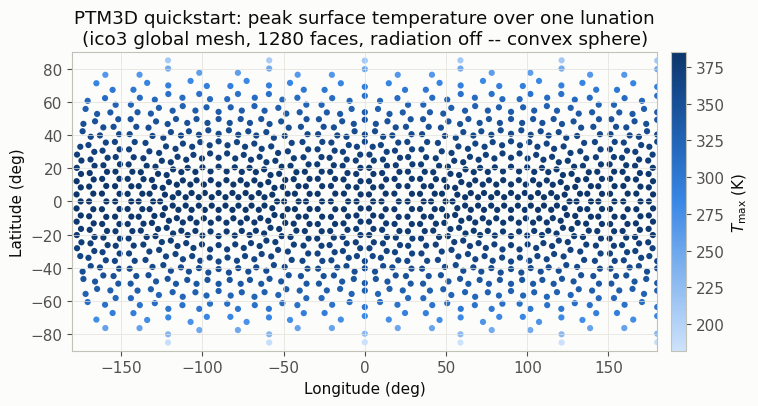

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.2))
sc = ax.scatter(lon, lat, c=stats["temperature_max"], cmap=seq_blue,
                 s=20, linewidths=0)
ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)
ax.set_xlabel("Longitude (deg)")
ax.set_ylabel("Latitude (deg)")
ax.set_title(f"PTM3D quickstart: peak surface temperature over one lunation\n"
             f"(ico3 global mesh, {len(lat)} faces, radiation off -- convex sphere)")
ax.grid(True, linewidth=0.5)
cb = fig.colorbar(sc, ax=ax, pad=0.02)
cb.set_label(r"$T_\mathrm{max}$ (K)")
plt.tight_layout()
plt.show()


Equatorial face: index 256, lat=0.00 deg, lon=126.00 deg


240 output steps spanning 707.2 h (29.5 d); cadence 2.96 h/step
face 256 curve: min=94.1 K, max=384.5 K


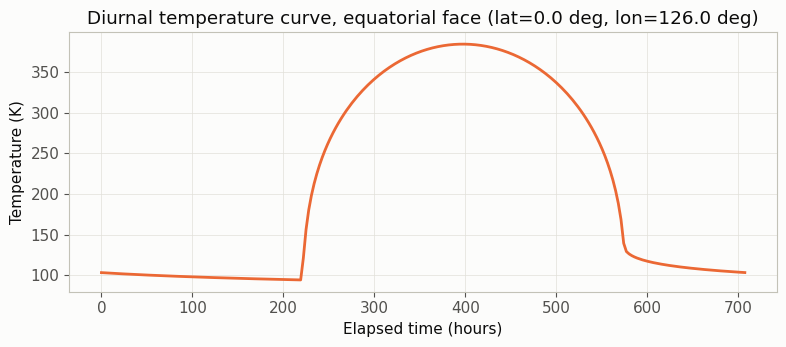

In [10]:
# Pick one equatorial face deterministically (nearest to lat=0) and read its
# full diurnal curve -- 240 small reads, same load_bin() reader as above.
eq_face = int(np.argmin(np.abs(lat)))
print(f"Equatorial face: index {eq_face}, lat={lat[eq_face]:.2f} deg, "
      f"lon={lon[eq_face]:.2f} deg")

n_steps = cfg["simulation"]["timesteps"] if cfg else 240
temp_dir = OUT_DIR / "temperature"
curve = np.array([load_bin(temp_dir / f"temperature_{t:04d}.bin")[eq_face]
                   for t in range(n_steps)])

# time_steps.txt column 1 is seconds past the J2000 epoch (SPICE ET), NOT
# "elapsed from start" despite its own header comment -- confirmed in
# docs/tutorials/06_interpreting_outputs.md. Subtract the first value for an
# elapsed-time axis.
lines = [ln.split() for ln in (OUT_DIR / "time_steps.txt").read_text().splitlines()
         if ln.strip() and not ln.startswith("#")]
t_et = np.array([float(row[0]) for row in lines])
t_hr = (t_et - t_et[0]) / 3600.0
cadence_hr = float(np.median(np.diff(t_hr)))
print(f"{len(t_hr)} output steps spanning {t_hr[-1]:.1f} h "
      f"({t_hr[-1]/24:.1f} d); cadence {cadence_hr:.2f} h/step")
print(f"face {eq_face} curve: min={curve.min():.1f} K, max={curve.max():.1f} K")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(t_hr, curve, color=ACCENT_ORANGE, linewidth=2)
ax.set_xlabel("Elapsed time (hours)")
ax.set_ylabel("Temperature (K)")
ax.set_title(f"Diurnal temperature curve, equatorial face "
             f"(lat={lat[eq_face]:.1f} deg, lon={lon[eq_face]:.1f} deg)")
ax.grid(True, linewidth=0.5)
plt.tight_layout()
plt.show()


day/night contrast (Tmax-Tmin): min=115.6  max=290.7  mean=265.0 K  (n_distinct@0.1K=525, range=175.1 K)
correlation with |latitude|: r = -0.92


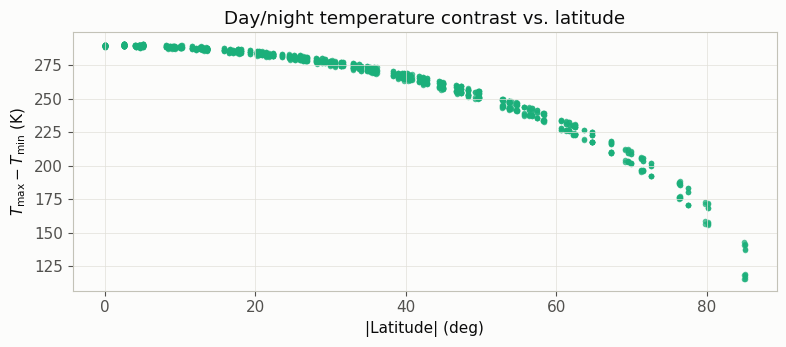

In [11]:
contrast = stats["temperature_max"] - stats["temperature_min"]
n_distinct_contrast = len(np.unique(np.round(contrast, 1)))
corr = float(np.corrcoef(np.abs(lat), contrast)[0, 1])
print(f"day/night contrast (Tmax-Tmin): min={contrast.min():.1f}  "
      f"max={contrast.max():.1f}  mean={contrast.mean():.1f} K  "
      f"(n_distinct@0.1K={n_distinct_contrast}, range={contrast.max()-contrast.min():.1f} K)")
print(f"correlation with |latitude|: r = {corr:.2f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(np.abs(lat), contrast, color=ACCENT_AQUA, s=16, alpha=0.75, linewidths=0)
ax.set_xlabel("|Latitude| (deg)")
ax.set_ylabel(r"$T_\mathrm{max} - T_\mathrm{min}$ (K)")
ax.set_title("Day/night temperature contrast vs. latitude")
ax.grid(True, linewidth=0.5)
plt.tight_layout()
plt.show()


## 5. Interpretation

**The diurnal wave.** The equatorial face's curve traces one full lunar day:
a slow ~350-hour rise to noon as the Sun climbs (the ~3 h output cadence
oversamples this comfortably relative to the ~709 h lunation), then an even
slower fall. Peak temperature and peak insolation land in the *same* output
step for this face — the true lag between them is shorter than the ~3 h
sampling interval, so it is not resolved here (Exercise 2 shows how to
resolve it).

**Thermal inertia** shows most clearly in the shape of the night side.
Insolation drops to zero at sunset in a single step (a geometric on/off), but
temperature does not follow it down: the surface cools quickly for the first
hour or two (radiating away the shallow layer's heat), then the cooling rate
drops sharply and the temperature glides down almost linearly for the rest of
the ~450-hour lunar night, bottoming out just before sunrise. The slow glide
is heat conducted up from the deeper, still-warm regolith layers, arriving at
the surface with a delay set by the thermal skin depth — the thermal-inertia
concept from `docs/tutorials/02_lunar_diurnal_icosphere.md` and the classic
Diviner nighttime-plateau observation it cites.

**Day/night contrast vs. latitude.** The scatter is close to a clean,
monotonically decreasing trend (correlation printed above, typically around
$r\approx-0.9$): near the equator the Sun reaches near-normal incidence at
noon (`temperature_max` close to the sub-solar blackbody limit) while the
nighttime floor is the same ~90-95 K everywhere, so the swing is largest
there. Toward the poles, grazing incidence caps `temperature_max` well below
the equatorial value while `temperature_min` drops only modestly, so the
swing narrows. This geometry is why polar regions are cold-trap territory
even before topographic shadowing — which tutorial 04's crater case adds — is
in play.


## 6. Exercises

1. **Sharper map, config change only.** Copy
   `examples/quickstart_moon_diurnal.yaml`, bump `mesh.resolution: 3` to
   `4` (1280 → 5120 faces, ~240 km pitch), and re-run section 2 against the
   new config/output directory. Still comfortably laptop-sized —
   `scripts/ptm_mem_estimate.py --faces 5120 --steps 240` gives the estimate.
   Re-run the temperature-map plot on the new output and compare the
   blockiness.

2. **Resolve the noon lag.** Peak insolation and peak temperature land in the
   *same* ~3 h output step above — the true thermal lag is shorter than that.
   Bump `simulation.timesteps` from `240` to `960` (~45 min/step; wall time
   and output size scale roughly with it) and re-run the "diurnal curve"
   cell's flux-vs-temperature comparison for the same equatorial face to see
   whether the peaks separate.

3. **Poles vs. equator, no re-run needed.** Everything after section 3 only
   depends on `lat`, `lon`, and the already-loaded arrays. Change
   `eq_face = int(np.argmin(np.abs(lat)))` to pick a near-polar face instead
   (e.g. `polar_face = int(np.argmax(np.abs(lat)))`) and re-plot its diurnal
   curve. Expect a much smaller swing (consistent with the day/night contrast
   plot) and a flatter shape — grazing incidence spreads a weaker flux over
   more of the "day."

**Note on thermophysical exercises:** `body: Moon` is a *built-in* body, and
plain-named thermophysical properties (`H`, `ks`, `kd`, `rhos`, `rhod`,
`albedo`, ...) in a config are not read on a named body — only
`use_default_albedo`, `incidence_angle_albedo`, and the
`*_override`/`*_model` keys are (see
[`docs/KNOWN_LIMITATIONS.md`](../../KNOWN_LIMITATIONS.md)), and there is no
config route to a non-default scalar `H` on a named body except
`h_parameter_map` (a per-face raster). A scalar-`H` sweep needs a custom
`generic_body:` block instead (e.g.
[`configs/amundsen_phase2_template.yaml`](../../../configs/amundsen_phase2_template.yaml),
which sets `H: 0.06` under `generic_body.surface:`). The exercises above
therefore vary what the Moon preset does expose (resolution, output cadence)
plus a config-free re-analysis (latitude) that shows the same physics.


## Version

The binary and commit that produced the numbers in this notebook.


In [12]:
import hashlib
import subprocess as sp

md5 = hashlib.md5(BINARY.read_bytes()).hexdigest()
print("Binary:", BINARY)
print("MD5:   ", md5)

try:
    commit = sp.run(
        ["/Library/Developer/CommandLineTools/usr/bin/git", "rev-parse", "HEAD"],
        cwd=str(REPO_ROOT), capture_output=True, text=True, check=True,
    ).stdout.strip()
    branch = sp.run(
        ["/Library/Developer/CommandLineTools/usr/bin/git", "rev-parse", "--abbrev-ref", "HEAD"],
        cwd=str(REPO_ROOT), capture_output=True, text=True, check=True,
    ).stdout.strip()
    print("Commit:", commit, f"({branch})")
except Exception as exc:  # pragma: no cover -- version info is best-effort
    print("(git information unavailable in this environment:", exc, ")")

print(f"\nWall time of the run in section 2: {wall_time_s:.1f} s")


Binary: /Users/paha3326/Projects/ptm-tutedit/build/bin/ptm_thermal_sim
MD5:    95bea53ffdac4e85671cc02fcfff1bba


Commit: 0b97202af7261426e8d5906708abfe13c312a4fd (docs/tutorials-editorial)

Wall time of the run in section 2: 5.3 s
